# MODULE 01: LOGISTIC REGRESSION FOR SERVER FAILURE PREDICTION

**Course:** Enterprise AI & Machine Learning Training Program
**Module:** 01 - Introduction to AI & ML
**Topic:** Classification & Logistic Regression
**Author:** Enterprise AI Training Team
**Version:** 2.0 (Complete)

---

## Overview
This comprehensive notebook teaches machine learning using Logistic Regression to predict server failures in enterprise IT infrastructure.

# SECTION 1: INTRODUCTION TO AI & MACHINE LEARNING

## What is Artificial Intelligence?
Artificial Intelligence (AI) is the field of computer science focused on creating systems that perform tasks requiring human-level intelligence.

## What is Machine Learning?
Machine Learning (ML) is a subset of AI where systems learn patterns from data without explicit programming.

## Types of Machine Learning
### Supervised Learning (Used Today)
- Training data includes inputs (X) and correct outputs (y)
- Two types:
  - **Regression:** Predict continuous values (e.g., temperature)
  - **Classification:** Predict categories (e.g., failure/no failure)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve, mean_squared_error, r2_score
)
import joblib

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

print('✓ All libraries imported successfully!')
print(f'✓ Pandas: {pd.__version__}')
print(f'✓ NumPy: {np.__version__}')
print('✓ Environment ready for Machine Learning!')

✓ All libraries imported successfully!
✓ Pandas: 2.2.2
✓ NumPy: 2.0.2
✓ Environment ready for Machine Learning!


# SECTION 2: DATA EXPLORATION & ANALYSIS

In [2]:
# Load dataset
df = pd.read_csv('server_failure_logistic_regression_21000.csv')

print('\n' + '='*80)
print('DATASET LOADED SUCCESSFULLY')
print('='*80)
print(f'Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'File Size: {df.memory_usage(deep=True).sum() / 1024:.2f} KB')


DATASET LOADED SUCCESSFULLY
Dataset Shape: 1032 rows × 17 columns
File Size: 469.28 KB


In [3]:
# Display dataset structure
print('\n' + '='*80)
print('DATASET STRUCTURE')
print('='*80)
print(df.info())
print('\n' + '='*80)
print('STATISTICAL SUMMARY')
print('='*80)
print(df.describe())


DATASET STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1032 entries, 0 to 1031
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   server_id           1032 non-null   object 
 1   datacenter          1032 non-null   object 
 2   region              1032 non-null   object 
 3   server_type         1032 non-null   object 
 4   operating_system    1032 non-null   object 
 5   cpu_usage_pct       1032 non-null   float64
 6   memory_usage_pct    1032 non-null   float64
 7   disk_usage_pct      1032 non-null   float64
 8   network_latency_ms  1032 non-null   float64
 9   temperature_c       1032 non-null   float64
 10  uptime_days         1032 non-null   int64  
 11  security_alerts     1032 non-null   int64  
 12  failed_processes    1032 non-null   int64  
 13  patch_age_days      1032 non-null   int64  
 14  backup_status       1032 non-null   object 
 15  service_priority    1032 non-null   

In [4]:
# Analyze target variable
print('\n' + '='*80)
print('TARGET VARIABLE ANALYSIS')
print('='*80)
print('\nServer Failure Distribution:')
print(df['server_failure'].value_counts())
print('\nPercentage:')
print(df['server_failure'].value_counts(normalize=True) * 100)
healthy = (df['server_failure'] == 0).sum()
failed = (df['server_failure'] == 1).sum()
print(f'\nClass Balance: {healthy} healthy, {failed} failure')
print(f'Imbalance Ratio: {healthy/failed:.2f}:1')


TARGET VARIABLE ANALYSIS

Server Failure Distribution:
server_failure
1    680
0    352
Name: count, dtype: int64

Percentage:
server_failure
1    65.891473
0    34.108527
Name: proportion, dtype: float64

Class Balance: 352 healthy, 680 failure
Imbalance Ratio: 0.52:1


# SECTION 3: FEATURE ENGINEERING & PREPROCESSING

Before training the model, we must prepare the data.

In [5]:
# Step 1: Identify categorical and numerical columns
print('\n' + '='*80)
print('FEATURE IDENTIFICATION')
print('='*80)

categorical_cols = df.select_dtypes(include='object').columns.tolist()
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

if 'server_failure' in numerical_cols:
    numerical_cols.remove('server_failure')

print(f'\nCategorical Features ({len(categorical_cols)}): {categorical_cols}')
print(f'Numerical Features ({len(numerical_cols)}): {numerical_cols}')


FEATURE IDENTIFICATION

Categorical Features (7): ['server_id', 'datacenter', 'region', 'server_type', 'operating_system', 'backup_status', 'service_priority']
Numerical Features (9): ['cpu_usage_pct', 'memory_usage_pct', 'disk_usage_pct', 'network_latency_ms', 'temperature_c', 'uptime_days', 'security_alerts', 'failed_processes', 'patch_age_days']


In [6]:
# Step 2: Encode categorical variables
print('\n' + '='*80)
print('ENCODING CATEGORICAL VARIABLES')
print('='*80)

df_processed = df.copy()
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col])
    label_encoders[col] = le
    print(f'\n{col}: {df[col].nunique()} unique values encoded')

print('\n✓ All categorical variables encoded successfully!')


ENCODING CATEGORICAL VARIABLES

server_id: 1032 unique values encoded

datacenter: 4 unique values encoded

region: 4 unique values encoded

server_type: 4 unique values encoded

operating_system: 4 unique values encoded

backup_status: 2 unique values encoded

service_priority: 4 unique values encoded

✓ All categorical variables encoded successfully!


In [7]:
# Step 3: Separate features and target
print('\n' + '='*80)
print('SEPARATING FEATURES AND TARGET')
print('='*80)

X = df_processed.drop('server_failure', axis=1)
y = df_processed['server_failure']

print(f'\nFeatures (X) shape: {X.shape}')
print(f'Target (y) shape: {y.shape}')
print(f'\nTarget value counts:')
print(y.value_counts())


SEPARATING FEATURES AND TARGET

Features (X) shape: (1032, 16)
Target (y) shape: (1032,)

Target value counts:
server_failure
1    680
0    352
Name: count, dtype: int64


In [8]:
# Step 4: Train-Test Split
print('\n' + '='*80)
print('TRAIN-TEST SPLIT')
print('='*80)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'\nTraining set size: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Testing set size: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)')
print(f'\n✓ Data split completed with stratification')


TRAIN-TEST SPLIT

Training set size: 825 samples (79.9%)
Testing set size: 207 samples (20.1%)

✓ Data split completed with stratification


In [9]:
# Step 5: Feature Scaling
print('\n' + '='*80)
print('FEATURE SCALING (STANDARDIZATION)')
print('='*80)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

print(f'\n✓ All features scaled successfully!')


FEATURE SCALING (STANDARDIZATION)

✓ All features scaled successfully!


# SECTION 4: MODEL TRAINING

In [10]:
# Step 1: Instantiate the model
print('\n' + '='*80)
print('INSTANTIATING LOGISTIC REGRESSION MODEL')
print('='*80)

model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver='lbfgs',
    n_jobs=-1
)

print('\nLogistic Regression Model Created')


INSTANTIATING LOGISTIC REGRESSION MODEL

Logistic Regression Model Created


In [11]:
# Step 2: Train the model
print('\n' + '='*80)
print('TRAINING THE MODEL')
print('='*80)

model.fit(X_train_scaled, y_train)

print('\n✓ Model trained successfully!')
print(f'Model Intercept: {model.intercept_[0]:.6f}')
print(f'Number of features: {model.n_features_in_}')


TRAINING THE MODEL

✓ Model trained successfully!
Model Intercept: 0.882849
Number of features: 16


In [12]:
# Step 3: Make predictions
print('\n' + '='*80)
print('GENERATING PREDICTIONS')
print('='*80)

y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

y_train_pred_proba = model.predict_proba(X_train_scaled)[:, 1]
y_test_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print('\n✓ Predictions generated successfully!')


GENERATING PREDICTIONS

✓ Predictions generated successfully!


# SECTION 5: MODEL EVALUATION & PERFORMANCE METRICS

In [13]:
# Training set metrics
print('\n' + '='*80)
print('MODEL PERFORMANCE EVALUATION - TRAIN SET')
print('='*80)

train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)
train_auc = roc_auc_score(y_train, y_train_pred_proba)

print(f'\nAccuracy:  {train_accuracy:.4f} ({train_accuracy*100:.2f}%)')
print(f'Precision: {train_precision:.4f} ({train_precision*100:.2f}%)')
print(f'Recall:    {train_recall:.4f} ({train_recall*100:.2f}%)')
print(f'F1-Score:  {train_f1:.4f}')
print(f'MSE:       {train_mse:.4f}')
print(f'R² Score:  {train_r2:.4f}')
print(f'ROC-AUC:   {train_auc:.4f}')


MODEL PERFORMANCE EVALUATION - TRAIN SET

Accuracy:  0.7321 (73.21%)
Precision: 0.7592 (75.92%)
Recall:    0.8695 (86.95%)
F1-Score:  0.8106
MSE:       0.2679
R² Score:  -0.1927
ROC-AUC:   0.7874


In [14]:
# Test set metrics
print('\n' + '='*80)
print('MODEL PERFORMANCE EVALUATION - TEST SET')
print('='*80)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_pred_proba)

print(f'\nAccuracy:  {test_accuracy:.4f} ({test_accuracy*100:.2f}%)')
print(f'Precision: {test_precision:.4f} ({test_precision*100:.2f}%)')
print(f'Recall:    {test_recall:.4f} ({test_recall*100:.2f}%)')
print(f'F1-Score:  {test_f1:.4f}')
print(f'MSE:       {test_mse:.4f}')
print(f'R² Score:  {test_r2:.4f}')
print(f'ROC-AUC:   {test_auc:.4f}')


MODEL PERFORMANCE EVALUATION - TEST SET

Accuracy:  0.7295 (72.95%)
Precision: 0.7597 (75.97%)
Recall:    0.8603 (86.03%)
F1-Score:  0.8069
MSE:       0.2705
R² Score:  -0.2005
ROC-AUC:   0.7635


In [15]:
# Confusion Matrix
print('\n' + '='*80)
print('CONFUSION MATRIX - TEST SET')
print('='*80)

cm = confusion_matrix(y_test, y_test_pred)
print('\n', cm)

tn, fp, fn, tp = cm.ravel()
print('\nConfusion Matrix Breakdown:')
print(f'  True Negatives (TN):  {tn}')
print(f'  False Positives (FP): {fp}')
print(f'  False Negatives (FN): {fn}')
print(f'  True Positives (TP):  {tp}')


CONFUSION MATRIX - TEST SET

 [[ 34  37]
 [ 19 117]]

Confusion Matrix Breakdown:
  True Negatives (TN):  34
  False Positives (FP): 37
  False Negatives (FN): 19
  True Positives (TP):  117


In [16]:
# Classification Report
print('\n' + '='*80)
print('DETAILED CLASSIFICATION REPORT - TEST SET')
print('='*80)
print('\n', classification_report(y_test, y_test_pred, target_names=['Healthy', 'Failure']))


DETAILED CLASSIFICATION REPORT - TEST SET

               precision    recall  f1-score   support

     Healthy       0.64      0.48      0.55        71
     Failure       0.76      0.86      0.81       136

    accuracy                           0.73       207
   macro avg       0.70      0.67      0.68       207
weighted avg       0.72      0.73      0.72       207



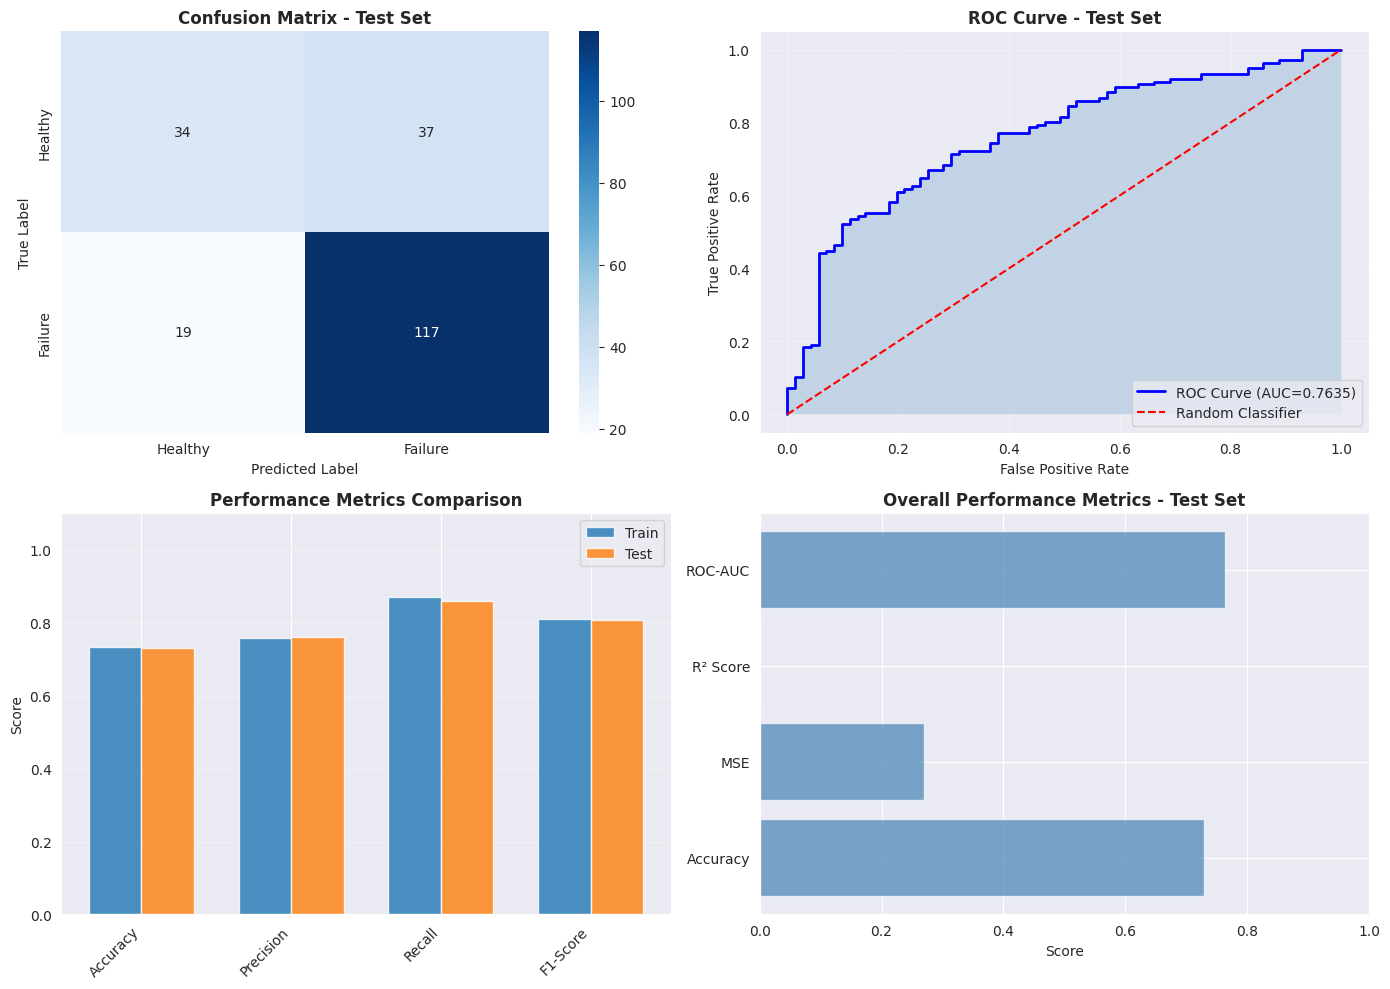


✓ Visualizations generated successfully!


In [17]:
# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
            xticklabels=['Healthy', 'Failure'], yticklabels=['Healthy', 'Failure'])
axes[0, 0].set_title('Confusion Matrix - Test Set', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('True Label')
axes[0, 0].set_xlabel('Predicted Label')

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_pred_proba)
axes[0, 1].plot(fpr, tpr, 'b-', label=f'ROC Curve (AUC={test_auc:.4f})', linewidth=2)
axes[0, 1].plot([0, 1], [0, 1], 'r--', label='Random Classifier', linewidth=1.5)
axes[0, 1].fill_between(fpr, tpr, alpha=0.2)
axes[0, 1].set_xlabel('False Positive Rate')
axes[0, 1].set_ylabel('True Positive Rate')
axes[0, 1].set_title('ROC Curve - Test Set', fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='lower right')
axes[0, 1].grid(alpha=0.3)

# 3. Metrics Comparison
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
train_metrics = [train_accuracy, train_precision, train_recall, train_f1]
test_metrics = [test_accuracy, test_precision, test_recall, test_f1]
x = np.arange(len(metrics_names))
width = 0.35
axes[1, 0].bar(x - width/2, train_metrics, width, label='Train', alpha=0.8)
axes[1, 0].bar(x + width/2, test_metrics, width, label='Test', alpha=0.8)
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Performance Metrics Comparison', fontsize=12, fontweight='bold')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(metrics_names, rotation=45, ha='right')
axes[1, 0].legend()
axes[1, 0].set_ylim([0, 1.1])
axes[1, 0].grid(alpha=0.3, axis='y')

# 4. Error Metrics
error_metrics_names = ['Accuracy', 'MSE', 'R² Score', 'ROC-AUC']
error_metrics_values = [test_accuracy, test_mse, test_r2, test_auc]
axes[1, 1].barh(error_metrics_names, error_metrics_values, color='steelblue', alpha=0.7)
axes[1, 1].set_xlabel('Score')
axes[1, 1].set_title('Overall Performance Metrics - Test Set', fontsize=12, fontweight='bold')
axes[1, 1].set_xlim([0, 1])

plt.tight_layout()
plt.show()

print('\n✓ Visualizations generated successfully!')

# SECTION 6: MODEL INTERPRETATION & FEATURE ANALYSIS

In [18]:
# Feature Importance
print('\n' + '='*80)
print('FEATURE IMPORTANCE ANALYSIS')
print('='*80)

coefficients = model.coef_[0]
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients,
    'Absolute_Coefficient': np.abs(coefficients)
}).sort_values('Absolute_Coefficient', ascending=False)

print('\nTop 10 Most Important Features:')
print(feature_importance.head(10).to_string(index=False))


FEATURE IMPORTANCE ANALYSIS

Top 10 Most Important Features:
           Feature  Coefficient  Absolute_Coefficient
   security_alerts     0.596949              0.596949
  failed_processes     0.537564              0.537564
     backup_status     0.509600              0.509600
  service_priority    -0.456911              0.456911
     cpu_usage_pct     0.408861              0.408861
       uptime_days    -0.400559              0.400559
  memory_usage_pct     0.354219              0.354219
    disk_usage_pct     0.277418              0.277418
network_latency_ms     0.260880              0.260880
    patch_age_days     0.234258              0.234258


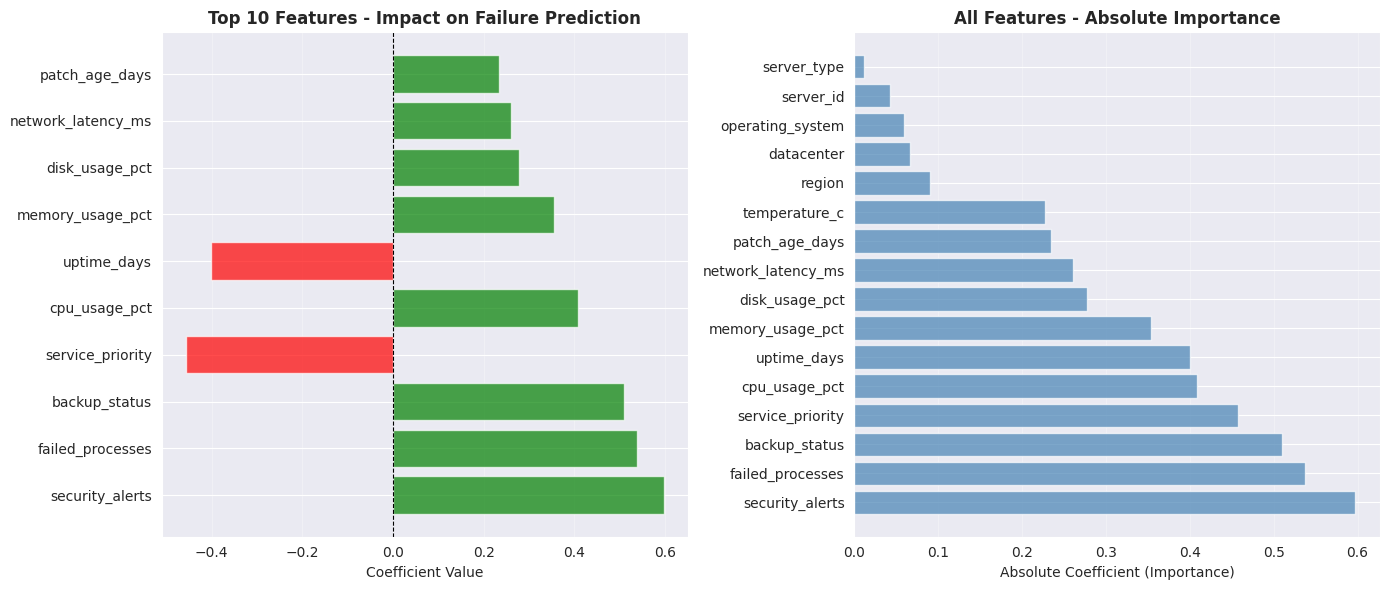


✓ Feature importance visualization complete!


In [19]:
# Visualize feature importance
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_10 = feature_importance.head(10)
colors = ['green' if x > 0 else 'red' for x in top_10['Coefficient']]
axes[0].barh(top_10['Feature'], top_10['Coefficient'], color=colors, alpha=0.7)
axes[0].set_xlabel('Coefficient Value')
axes[0].set_title('Top 10 Features - Impact on Failure Prediction', fontsize=12, fontweight='bold')
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=0.8)
axes[0].grid(alpha=0.3, axis='x')

axes[1].barh(feature_importance['Feature'], feature_importance['Absolute_Coefficient'], color='steelblue', alpha=0.7)
axes[1].set_xlabel('Absolute Coefficient (Importance)')
axes[1].set_title('All Features - Absolute Importance', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print('\n✓ Feature importance visualization complete!')

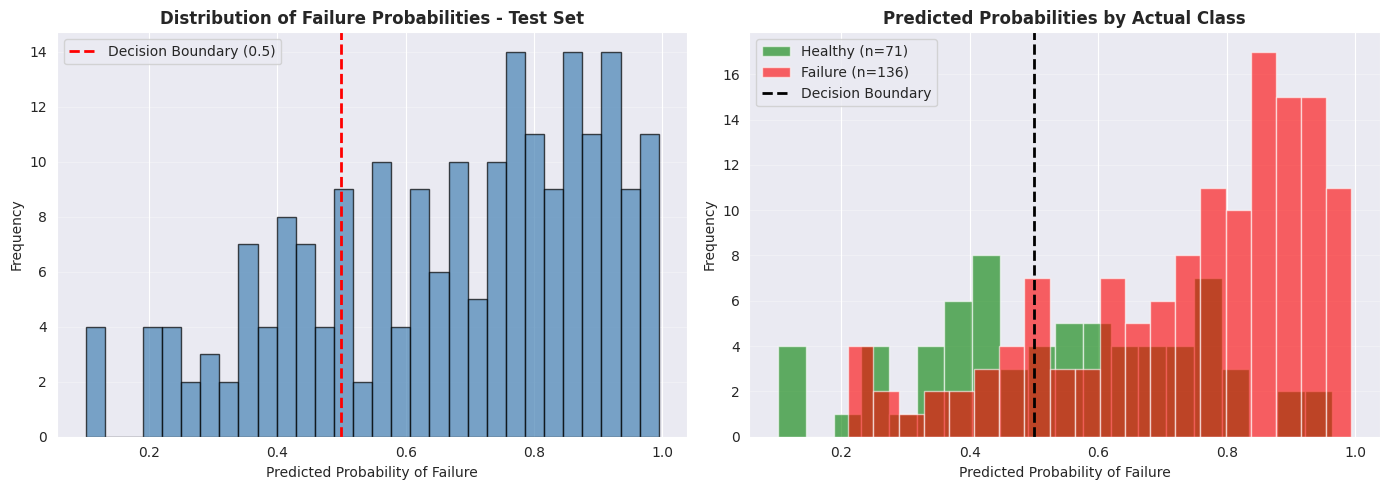

In [20]:
# Probability distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(y_test_pred_proba, bins=30, alpha=0.7, color='steelblue', edgecolor='black')
axes[0].axvline(x=0.5, color='red', linestyle='--', linewidth=2, label='Decision Boundary (0.5)')
axes[0].set_xlabel('Predicted Probability of Failure')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Failure Probabilities - Test Set', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3, axis='y')

prob_healthy = y_test_pred_proba[y_test == 0]
prob_failure = y_test_pred_proba[y_test == 1]

axes[1].hist(prob_healthy, bins=20, alpha=0.6, label=f'Healthy (n={len(prob_healthy)})', color='green')
axes[1].hist(prob_failure, bins=20, alpha=0.6, label=f'Failure (n={len(prob_failure)})', color='red')
axes[1].axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='Decision Boundary')
axes[1].set_xlabel('Predicted Probability of Failure')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Predicted Probabilities by Actual Class', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# SECTION 7: BUSINESS DISCUSSION & REAL-WORLD APPLICATIONS

In [21]:
print('\n' + '='*80)
print('BUSINESS CONTEXT & REAL-WORLD APPLICATION')
print('='*80)
print('''
╔════════════════════════════════════════════════════════════════════════════════╗
║                    HOW THIS MODEL SUPPORTS IT OPERATIONS                        ║
╚════════════════════════════════════════════════════════════════════════════════╝

1. PROACTIVE INFRASTRUCTURE MANAGEMENT
   → Predict failures 7-14 days before they happen
   → Schedule maintenance during planned windows
   → Prevent unexpected downtime

2. COST-BENEFIT ANALYSIS
   • Cost to PREVENT failure: ~$2,000 (scheduled maintenance)
   • Cost of MISSED failure: ~$50,000+ (emergency response + lost revenue)
   • ROI = (Savings per prevented failure) × (Correct predictions)

3. RESOURCE OPTIMIZATION
   • Predict failures in advance
   • Schedule maintenance during off-peak hours
   • Reduce emergency on-call incidents
   • Optimize IT staff allocation
''')


BUSINESS CONTEXT & REAL-WORLD APPLICATION

╔════════════════════════════════════════════════════════════════════════════════╗
║                    HOW THIS MODEL SUPPORTS IT OPERATIONS                        ║
╚════════════════════════════════════════════════════════════════════════════════╝

1. PROACTIVE INFRASTRUCTURE MANAGEMENT
   → Predict failures 7-14 days before they happen
   → Schedule maintenance during planned windows
   → Prevent unexpected downtime

2. COST-BENEFIT ANALYSIS
   • Cost to PREVENT failure: ~$2,000 (scheduled maintenance)
   • Cost of MISSED failure: ~$50,000+ (emergency response + lost revenue)
   • ROI = (Savings per prevented failure) × (Correct predictions)

3. RESOURCE OPTIMIZATION
   • Predict failures in advance
   • Schedule maintenance during off-peak hours
   • Reduce emergency on-call incidents
   • Optimize IT staff allocation



In [22]:
# Business metrics
print('\n' + '='*80)
print('QUANTIFIED BUSINESS IMPACT')
print('='*80)

total_servers = len(y_test)
actual_failures = (y_test == 1).sum()

print(f'\nTest Set Analysis ({total_servers} servers monitored):')
print(f'  • Servers that actually failed: {actual_failures}')
print(f'\nModel Performance:')
print(f'  • Recall (failures caught): {test_recall*100:.1f}%')
print(f'  • Precision (false alarm rate): {test_precision*100:.1f}%')
print(f'  • Accuracy (overall correctness): {test_accuracy*100:.1f}%')

cost_per_prevented = 2000
cost_per_missed = 50000
cost_per_false = 500

prevented_value = tp * cost_per_prevented
missed_cost = fn * cost_per_missed
false_cost = fp * cost_per_false

print(f'\nEstimated Financial Impact:')
print(f'  • Value of prevented failures: ${prevented_value:,}')
print(f'  • Cost of missed failures: $({missed_cost:,})')
print(f'  • Cost of false alarms: $({false_cost:,})')


QUANTIFIED BUSINESS IMPACT

Test Set Analysis (207 servers monitored):
  • Servers that actually failed: 136

Model Performance:
  • Recall (failures caught): 86.0%
  • Precision (false alarm rate): 76.0%
  • Accuracy (overall correctness): 72.9%

Estimated Financial Impact:
  • Value of prevented failures: $234,000
  • Cost of missed failures: $(950,000)
  • Cost of false alarms: $(18,500)


In [23]:
# Deployment recommendations
print('\n' + '='*80)
print('DEPLOYMENT RECOMMENDATIONS')
print('='*80)
print('''
1. MODEL INTEGRATION
   ✓ Deploy in production monitoring system
   ✓ Run predictions weekly/daily on all servers
   ✓ Trigger alerts when failure probability > 0.7

2. MONITORING & ALERTING
   • LOW RISK (prob 0.3-0.5): Schedule maintenance within 30 days
   • MEDIUM RISK (prob 0.5-0.7): Schedule maintenance within 14 days
   • HIGH RISK (prob > 0.7): Schedule maintenance within 7 days

3. CONTINUOUS IMPROVEMENT
   • Retrain model monthly with new data
   • Monitor prediction accuracy on actual failures
   • Adjust thresholds based on business needs
''')


DEPLOYMENT RECOMMENDATIONS

1. MODEL INTEGRATION
   ✓ Deploy in production monitoring system
   ✓ Run predictions weekly/daily on all servers
   ✓ Trigger alerts when failure probability > 0.7

2. MONITORING & ALERTING
   • LOW RISK (prob 0.3-0.5): Schedule maintenance within 30 days
   • MEDIUM RISK (prob 0.5-0.7): Schedule maintenance within 14 days
   • HIGH RISK (prob > 0.7): Schedule maintenance within 7 days

3. CONTINUOUS IMPROVEMENT
   • Retrain model monthly with new data
   • Monitor prediction accuracy on actual failures
   • Adjust thresholds based on business needs



In [24]:
# Save model
print('\n' + '='*80)
print('MODEL PERSISTENCE & DEPLOYMENT')
print('='*80)

joblib.dump(model, 'logistic_regression_server_failure_model.pkl')
joblib.dump(scaler, 'feature_scaler.pkl')
joblib.dump(label_encoders, 'label_encoders.pkl')

print('\n✓ Models saved for production deployment:')
print('  • Model: logistic_regression_server_failure_model.pkl')
print('  • Scaler: feature_scaler.pkl')
print('  • Encoders: label_encoders.pkl')

print('\nModel successfully trained and saved!')
print('Ready for production deployment.')


MODEL PERSISTENCE & DEPLOYMENT

✓ Models saved for production deployment:
  • Model: logistic_regression_server_failure_model.pkl
  • Scaler: feature_scaler.pkl
  • Encoders: label_encoders.pkl

Model successfully trained and saved!
Ready for production deployment.
